In [1]:
import pandas as pd
import numpy as np 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

In [4]:
#how to read a file
flights = pd.read_parquet("../data/flights_sample.parquet")
flights.head()

,searchDate,flightDate,startingAirport,destinationAirport,travelDuration,isBasicEconomy,isNonStop,totalFare,seatsRemaining,totalTravelDistance,segmentsAirlineName
0,2022-04-18,2022-05-29,DFW,MIA,PT2H51M,False,True,342.6,7,1115.0,American Airlines
1,2022-04-16,2022-04-26,DFW,ATL,PT2H3M,True,True,133.6,9,725.0,Delta
2,2022-04-17,2022-06-10,LAX,SFO,PT1H24M,False,True,218.6,7,339.0,JetBlue Airways
3,2022-04-17,2022-06-03,DEN,PHL,PT7H14M,False,False,339.6,9,1671.0,Delta||Delta
4,2022-04-16,2022-04-23,BOS,LAX,PT9H10M,True,False,221.6,9,2674.0,Delta||Delta


In [5]:
#how to get columns 
flights["startingAirport"]          #returns the column startingAirport as a series (think of it as a list), can only take one column at a time
flights[["searchDate", "seatsRemaining"]] #

,searchDate,seatsRemaining
0,2022-04-18,7
1,2022-04-16,9
2,2022-04-17,7
3,2022-04-17,9
4,2022-04-16,9
...,...,...
4106933,2022-10-05,7
4106934,2022-10-05,0
4106935,2022-10-05,6
4106936,2022-10-05,4


In [6]:
#finds row based on indices
flights.iloc[0]

#finds row based on name of row
flights.loc[0]

searchDate             2022-04-18 00:00:00
flightDate             2022-05-29 00:00:00
startingAirport                        DFW
destinationAirport                     MIA
travelDuration                     PT2H51M
isBasicEconomy                       False
isNonStop                             True
totalFare                            342.6
seatsRemaining                           7
totalTravelDistance                 1115.0
segmentsAirlineName      American Airlines
Name: 0, dtype: object

In [7]:
#how to create new columns
flights["days inbetween seach and flight"] = flights["flightDate"] - flights["searchDate"] 
flights.head()

,searchDate,flightDate,startingAirport,destinationAirport,travelDuration,isBasicEconomy,isNonStop,totalFare,seatsRemaining,totalTravelDistance,segmentsAirlineName,days inbetween seach and flight
0,2022-04-18,2022-05-29,DFW,MIA,PT2H51M,False,True,342.6,7,1115.0,American Airlines,41 days
1,2022-04-16,2022-04-26,DFW,ATL,PT2H3M,True,True,133.6,9,725.0,Delta,10 days
2,2022-04-17,2022-06-10,LAX,SFO,PT1H24M,False,True,218.6,7,339.0,JetBlue Airways,54 days
3,2022-04-17,2022-06-03,DEN,PHL,PT7H14M,False,False,339.6,9,1671.0,Delta||Delta,47 days
4,2022-04-16,2022-04-23,BOS,LAX,PT9H10M,True,False,221.6,9,2674.0,Delta||Delta,7 days


In [8]:
#how to get a index dataframes based on condition
flights[flights["segmentsAirlineName"] == "Delta"]              #creates a new dataframe where segmentsAirlineName is delta
flights[flights["totalFare"] < 100] 

,searchDate,flightDate,startingAirport,destinationAirport,travelDuration,isBasicEconomy,isNonStop,totalFare,seatsRemaining,totalTravelDistance,segmentsAirlineName,days inbetween seach and flight
36,2022-04-17,2022-06-06,LGA,IAD,PT1H38M,True,True,98.60,9,221.0,United,50 days
55,2022-04-17,2022-06-15,BOS,MIA,PT3H32M,True,True,73.60,9,1260.0,Delta,59 days
56,2022-04-17,2022-05-17,SFO,LAX,PT1H35M,False,True,58.60,7,339.0,JetBlue Airways,30 days
115,2022-04-17,2022-06-06,IAD,LGA,PT1H31M,True,True,98.60,9,221.0,United,50 days
116,2022-04-17,2022-05-14,MIA,EWR,PT3H9M,False,True,66.97,0,NaN,Spirit Airlines,27 days
...,...,...,...,...,...,...,...,...,...,...,...,...
4106905,2022-10-05,2022-11-02,MIA,LGA,PT2H57M,False,True,98.60,7,1095.0,American Airlines,28 days
4106915,2022-10-05,2022-11-09,ATL,DTW,PT8H29M,False,False,76.58,0,NaN,Spirit Airlines||Spirit Airlines,35 days
4106919,2022-10-05,2022-11-04,EWR,BOS,PT1H25M,True,True,83.60,9,191.0,Delta,30 days
4106921,2022-10-05,2022-11-07,BOS,EWR,PT4H18M,True,False,92.60,9,NaN,United||United,33 days


In [9]:
#how to check for NaN values
flights.isna().any()

searchDate                         False
flightDate                         False
startingAirport                    False
destinationAirport                 False
travelDuration                     False
isBasicEconomy                     False
isNonStop                          False
totalFare                          False
seatsRemaining                     False
totalTravelDistance                 True
segmentsAirlineName                False
days inbetween seach and flight    False
dtype: bool

In [10]:
#imputation how to replace the missing values with the mean
flights["totalTravelDistance"] = flights["totalTravelDistance"].fillna(np.mean(flights["totalTravelDistance"]))

In [11]:
#getting training data and test data
X = flights[["totalTravelDistance"]]
y = flights["totalFare"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.8, random_state= 0)

In [12]:
#linear model
linearmodel = LinearRegression()
linearmodel.fit(X_train, y_train)
y_pred = linearmodel.predict(X_test)

In [13]:
#evaluating linear model
mean_squared_error(y_test, y_pred)

29883.474259488354

In [14]:
#createing polynomial value (x^2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)   # fit + transform on train
X_test_poly  = poly.transform(X_test)        # transform only on test

poly2model = LinearRegression(fit_intercept=False) #set fit_intercept to False to avoid having 2 intercepts
poly2model.fit(X_train_poly, y_train)             # y 
poly2model.predict(X_test_poly)

array([145.94440203, 466.47080762, 236.32010864, ..., 477.5501529 ,
       279.08500215, 369.52683347])

/Users/kyay/uc-davis-workspace/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


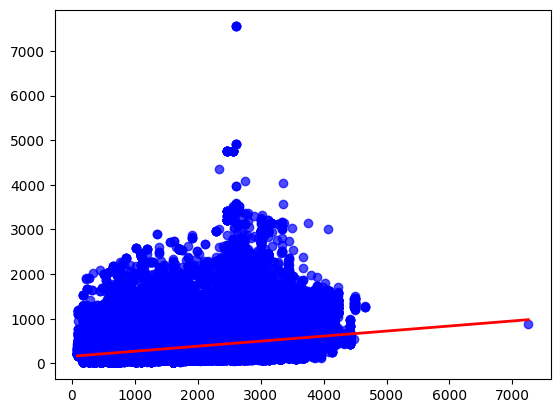

In [15]:
#graphing linear, will go more indepth on third week
smooth_line_x = np.linspace(X_train.min(), X_train.max(), 100)
smooth_line_y = linearmodel.predict(np.linspace(X_train.min(), X_train.max(), 100))
plt.scatter(X_train, y_train, color='blue', label='Actual Data', alpha=0.7)
plt.plot(smooth_line_x, smooth_line_y, color='red', linewidth=2, label='predicted data')

/Users/kyay/uc-davis-workspace/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


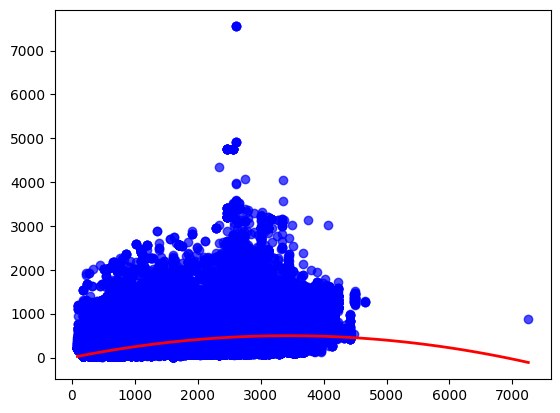

In [16]:
#graphing polynomial (x^2), will go more indepth on third week
smooth_line_x = np.linspace(X_train.min(), X_train.max(), 100)
smooth_line_poly_x = poly.transform(np.linspace(X_train.min(), X_train.max(), 100))
smooth_line_y = poly2model.predict(smooth_line_poly_x)
plt.scatter(X_train, y_train, color='blue', label='Actual Data', alpha=0.7)
plt.plot(smooth_line_x, smooth_line_y, color='red', linewidth=2, label='predicted data')